### 1. Data Ingestion & Initial Inspection

### Introduction and Goals

The cleaned transactions (`train`) and the cleaned customer table (`clientes`) are merged into one dataset, split into training and validation folds, and pre-processed in order: Missing Values, outliers, Encoding and Scaling.

| Section | Action | Output file (train / test) |
| :--- | :--- | :--- |
| **1.1** | Load `train`, `clientes` and `test` | `(no file written)` |
| **1.2** | Merge transactions with customers (left join, many-to-one) | `merge_1_2.csv` / `merge_1_2_test.csv` |
| **1.3** | Separate identifiers, target, numeric and categorical features | `(no file written)` |
| **1.4** | Missing values overview | `(no file written)` |
| **1.5** | Evaluation setup, temporal splits and baseline | `(no file written)` |
| **1.6** | Compare fill plans and fill the missing values (`median` / `mode`) | `merge_1_6.csv` / `merge_1_6_test.csv` |
| **1.7** | Outlier detection and treatment (`log1p`) | `merge_1_7.csv` / `merge_1_7_test.csv` |
| **1.8** | One-hot encoding of the categorical features (1.8.1) and scaling of the numeric ones (1.8.2) | `1_8_1.csv` / `1_8_1_test.csv`, `1_8_2.csv` / `1_8_2_test.csv` |

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re 

### Loading Data

In [2]:
trainFile = "../../../data/train.csv"
testFile = "../../../data/test.csv"
df = pd.read_csv(trainFile)
df_test = pd.read_csv(testFile)

print("Dataset Dimention (Rows, Columns):", df.shape)
print("Test Dataset Dimention (Rows, Columns):", df_test.shape)

print("\n--- First 5 Rows (Train) ---")
display(df.head())

print("\n--- First 5 Rows (Test) ---")
display(df_test.head())


Dataset Dimention (Rows, Columns): (6534, 39)
Test Dataset Dimention (Rows, Columns): (986, 38)

--- First 5 Rows (Train) ---


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890



--- First 5 Rows (Test) ---


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.37,582.05,232.82,53.55,0.0,0.0,349.23,104.409267,22,1,...,519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.621602
1,1949.25,1725.00,1725.00,224.25,0.0,0.0,0.00,0.000000,1,1,...,942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.318874
2,2738.71,4114.83,2738.71,0.00,0.0,0.0,1376.12,1019.466586,99,1,...,386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.251905
3,726.98,591.04,591.04,135.94,0.0,0.0,0.00,341.649008,39,2,...,588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988362
4,670.76,555.49,545.33,125.43,0.0,0.0,10.16,326.715748,13,1,...,610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.511535


### 1.1. Feature Overview & Data Types
The following code snippet displays the full list of features, their respective non-null counts, and inferred data types.

In [3]:
print("\n--- Datatype Information ---")
display(df.info())

print("\n--- Datatype Information (Test) ---")
display(df_test.info())


--- Datatype Information ---
<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure

None


--- Datatype Information (Test) ---
<class 'pandas.DataFrame'>
RangeIndex: 986 entries, 0 to 985
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   986 non-null    float64
 1   Total Bruto                     986 non-null    float64
 2   Total Liquido                   986 non-null    float64
 3   Total Imp_                      986 non-null    float64
 4   Total Portes                    986 non-null    float64
 5   Total Desc_ Global              986 non-null    float64
 6   Total Desc_ Linha               986 non-null    float64
 7   Custo                           986 non-null    float64
 8   N_ Detalhes                     986 non-null    int64  
 9   invoice_count_current_purchase  986 non-null    int64  
 10  days_since_previous_purchase    934 non-null    float64
 11  customer_tenure_days            986 non-null    int64  
 12  prior_purc

None

### 1.2. Analysis of Duplicates and Customer Repeat Purchases

To ensure data integrity and understand the granularity of our dataset, we performed two key checks:
1. **Duplicate rows, ignoring identifiers:** `ID` and `random_noise` differ in every row by construction, so a plain `df.duplicated()` can never find anything. We therefore drop those two columns before looking for repeated rows.
2. **Granularity & customer repetition (`customer_id`):** We examined the frequency of transactions per customer. Several records sharing the same `customer_id` are not errors; they are returning customers who bought more than once.

In [4]:
id_cols = ["ID", "random_noise"]   # differ in every row by construction, so they are ignored

duplicate_rows = df.drop(columns=id_cols, errors="ignore").duplicated().sum()
print("duplicate rows ignoring ID and random_noise:", duplicate_rows)

per_customer = df.groupby("customer_id").size()

print(f"\nsurplus rows on 'customer_id': {df.duplicated(subset='customer_id').sum()}")
print(f"rows sharing a 'customer_id': {per_customer[per_customer > 1].sum()} across {(per_customer > 1).sum()} customers")

bins = [0, 1, 2, 5, 10, 20, 50, 100, np.inf]
labels = [
    '1 purchase',
    '2 purchases',
    '3-5 purchases',
    '6-10 purchases',
    '11-20 purchases',
    '21-50 purchases',
    '51-100 purchases',
    '>100 purchases'
]

customer_bins = pd.cut(per_customer, bins=bins, labels=labels).value_counts().sort_index()

print("\nrecords per customer (binned distribution):")
print(customer_bins.to_dict())

duplicate rows ignoring ID and random_noise: 10

surplus rows on 'customer_id': 5924
rows sharing a 'customer_id': 6377 across 453 customers

records per customer (binned distribution):
{'1 purchase': 157, '2 purchases': 84, '3-5 purchases': 119, '6-10 purchases': 84, '11-20 purchases': 73, '21-50 purchases': 70, '51-100 purchases': 20, '>100 purchases': 3}


In [5]:
duplicate_rows_test = df_test.drop(columns=id_cols, errors="ignore").duplicated().sum()
print("\n--- Test Dataset ---")
print("Duplicate rows in Test Dataset (ignoring ID and random_noise):", duplicate_rows_test)

per_customer_test = df_test.groupby("customer_id").size()

print(f"\nsurplus rows on 'customer_id' in Test Dataset: {df_test.duplicated(subset='customer_id').sum()}")
print(f"rows sharing a 'customer_id' in Test Dataset: {per_customer_test[per_customer_test > 1].sum()} across {(per_customer_test > 1).sum()} customers")

customer_bins_test = pd.cut(per_customer_test, bins=bins, labels=labels).value_counts().sort_index()

print("\nrecords per customer (binned distribution) in Test Dataset:")
print(customer_bins_test.to_dict())


--- Test Dataset ---
Duplicate rows in Test Dataset (ignoring ID and random_noise): 0

surplus rows on 'customer_id' in Test Dataset: 780
rows sharing a 'customer_id' in Test Dataset: 940 across 160 customers

records per customer (binned distribution) in Test Dataset:
{'1 purchase': 46, '2 purchases': 38, '3-5 purchases': 60, '6-10 purchases': 42, '11-20 purchases': 18, '21-50 purchases': 2, '51-100 purchases': 0, '>100 purchases': 0}


**Conclusion 1.2:** A plain `df.duplicated()` can never find anything, because `ID` and `random_noise` are different in every row. Ignoring them, the number of repeated rows is the one printed above; section 1.3 checks whether those rows are simply empty records. About half of the customers have several records (returning customers), which is consistent with a repeat-purchase target. The test set follows the same pattern, with fewer purchases per customer (it covers a shorter period).

### 1.3. Missing Value Analysis
To assess overall data completeness in the raw dataset, we generated a high-level summary of missing values (`NaN`).

This overview quantifies:
* **Rows with at least one missing value** (total count and percentage of the dataset).
* **Columns containing missing values** out of the total feature set.
* **Total missing cells** across the entire data frame.
* **The feature with the highest count of missing values** (`worst column`).

This summary establishes an initial baseline of data quality prior to any cleaning or imputation steps.

In [6]:
rows_with_null = df.isna().any(axis=1)
per_column = df.isna().sum()

rows_with_null_test = df_test.isna().any(axis=1)
per_column_test = df_test.isna().sum()

def display_missing_values_info(df, rows_with_null, per_column):
    return pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(df):,} ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {df.shape[1]}",
    "null cells": f"{df.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
    }).to_frame("missing values as the file arrives")

display(display_missing_values_info(df, rows_with_null, per_column))
display(display_missing_values_info(df_test, rows_with_null_test, per_column_test))

,missing values as the file arrives
rows with a null,"2,605 of 6,534 (39.87%)"
columns with a null,36 of 39
null cells,"9,818"
worst column,prior_std_gap_days (1478 nulls)


,missing values as the file arrives
rows with a null,281 of 986 (28.50%)
columns with a null,12 of 38
null cells,489
worst column,prior_mean_gap_days (76 nulls)


**Conclusion 1.3:** About 40% of the train rows have at least one null, so missing values cannot simply be dropped; they need an imputation strategy fitted on the training folds only. The cells below look at *how* the data is missing, because this changes how it should be treated.

In [7]:
id_cols = ["ID", "random_noise"]
feat_cols = [c for c in df.columns if c not in ["repeat_purchase_90d", "customer_id"] + id_cols]
num_feat_cols = [c for c in feat_cols if pd.api.types.is_numeric_dtype(df[c])]

# Completely empty rows (no information in any numeric feature)
empty_train = df[num_feat_cols].isna().all(axis=1)
empty_test = df_test[[c for c in num_feat_cols if c in df_test.columns]].isna().all(axis=1)
print("fully empty rows -> train:", empty_train.sum(), "| test:", empty_test.sum())

# Are the repeated rows (ignoring ID / random_noise) exactly these empty rows?
dup = df.drop(columns=id_cols, errors="ignore").duplicated()
print("repeated rows:", dup.sum(), "| of which fully empty:", (dup & empty_train).sum())

# Sentinel value in spend_365d
print("spend_365d >= 1e9 -> train:", (df["spend_365d"] >= 1e9).sum(),
      "| test:", (df_test["spend_365d"] >= 1e9).sum())

fully empty rows -> train: 65 | test: 0
repeated rows: 10 | of which fully empty: 10
spend_365d >= 1e9 -> train: 15 | test: 2


**Conclusion 1.3 (patterns):** 65 train rows (and none in test) are completely empty, with no information in any numeric feature. They account for all 10 repeated rows found in 1.2, so these are empty records rather than real repeated transactions. In addition, `spend_365d` contains an extreme placeholder value (1e9) in 15 train rows and 2 test rows, also visible as the maximum in the `describe()` below. It must be converted to `NaN` (or capped) before scaling; otherwise it dominates the mean and standard deviation.

### 1.4. Identification and Handling of Domain Inconsistencies (Negative Values)

In domain-specific feature engineering, certain numerical attributes—such as days elapsed, monetary amounts, and purchase values—must be non-negative by definition.

We identified columns where negative values represent domain inconsistencies or data anomalies:
* `days_since_previous_purchase`
* `prior_mean_purchase_value`
* `prior_mean_gap_days`
* `spend_365d`

To evaluate the impact of these anomalies, we temporarily replace negative values with `NaN` using `.mask(< 0)` and quantify how this transformation affects the total count of missing rows and missing cells across the dataset.


In [8]:
# Define numerical columns whose domain strictly forbids negative values
non_negative = [
    "days_since_previous_purchase", 
    "prior_mean_purchase_value", 
    "prior_mean_gap_days", 
    "spend_365d"
]

# Convert negative values in these columns to NaN to evaluate anomalies
df_cleaned = df.copy()
df_cleaned[non_negative] = df_cleaned[non_negative].mask(df_cleaned[non_negative] < 0)

# Calculate the impact on missing value counts
rows_before = df.isna().any(axis=1).sum()
rows_after = df_cleaned.isna().any(axis=1).sum()
cells_before = df.isna().sum().sum()
cells_after = df_cleaned.isna().sum().sum()

print(f"\nrows with a null: {rows_before:,} -> {rows_after:,} ({100 * rows_after / len(df):.2f}% of {len(df):,})")
print(f"null cells:       {cells_before:,} -> {cells_after:,}")




rows with a null: 2,605 -> 2,643 (40.45% of 6,534)
null cells:       9,818 -> 9,881


**Identification of invalid data:** In business terms, `days_since_previous_purchase`, `prior_mean_purchase_value`, `prior_mean_gap_days` and `spend_365d` cannot be negative.

**Treatment by invalidation:** Negative values are data-collection anomalies. Instead of deleting whole rows, the negative values are turned into `NaN` so they are imputed in pre-processing (fitted on training data only).

**Impact (train):** rows with at least one missing value rise from 2,605 to 2,643 (40.45% of the observations) and null cells from 9,818 to 9,881.

In [9]:
df_cleaned_test = df_test.copy()
df_cleaned_test[non_negative] = df_cleaned_test[non_negative].mask(df_cleaned_test[non_negative] < 0)

rows_before_test = df_test.isna().any(axis=1).sum()
rows_after_test = df_cleaned_test.isna().any(axis=1).sum()
cells_before_test = df_test.isna().sum().sum()
cells_after_test = df_cleaned_test.isna().sum().sum()

print(f"\nrows with a null in Test Dataset: {rows_before_test:,} -> {rows_after_test:,} ({100 * rows_after_test / len(df_test):.2f}% of {len(df_test):,})")
print(f"null cells in Test Dataset:       {cells_before_test:,} -> {cells_after_test:,}")


rows with a null in Test Dataset: 281 -> 287 (29.11% of 986)
null cells in Test Dataset:       489 -> 497


### 1.5 Descriptive Statistics
To fulfill the exploratory data analysis requirements, we generated descriptive summary statistics for all numerical features in the dataset. 

* **What it does:** The df.describe() function computes key statistical metrics—including the count, mean, standard deviation, minimum, maximum, and interquartile percentiles (25%, 50% median, and 75%)—for every numerical column.

* **Why we use it:** It allows us to quickly assess the central tendency and dispersion of our features, identify potential scale discrepancies, and spot initial anomalies or extreme outliers across monetary values, counts, and temporal gaps before proceeding to data cleaning.


In [10]:
# Display summary statistics for numerical features in the raw dataset
df.describe()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,ID,random_noise
count,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,...,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6469.000000,6.274000e+03,6534.000000,6.534000e+03,6469.000000
mean,925.556262,886.152705,773.336384,152.219878,1.151427,0.349907,112.466414,328.165040,21.524501,1.066007,...,457.141009,1.631937,1253.527977,3.374556,2650.599796,6.561601,2.396535e+06,506471.910621,1.000383e+07,-0.022140
std,1334.997733,1327.641086,1136.355723,225.262375,5.844091,5.116564,289.986307,519.507218,27.713419,0.310807,...,1191.231401,2.977981,2347.842270,5.460510,4020.267397,10.325535,4.884113e+07,266556.041526,2.218817e+03,1.001054
min,0.930000,0.830000,0.760000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.591152e+05,103940.000000,1.000000e+07,-3.529210
25%,188.920000,175.740000,154.380000,29.930000,0.000000,0.000000,0.000000,49.050000,4.000000,1.000000,...,0.000000,0.000000,0.000000,1.000000,149.160000,1.000000,6.377825e+02,258332.000000,1.000191e+07,-0.677770
50%,476.740000,445.740000,389.910000,79.740000,0.000000,0.000000,13.130000,152.540000,11.000000,1.000000,...,0.000000,1.000000,198.500000,2.000000,1117.680000,3.000000,2.426605e+03,489625.000000,1.000382e+07,-0.045714
75%,1087.670000,1036.700000,903.370000,184.840000,0.000000,0.000000,92.280000,396.061499,29.000000,1.000000,...,338.240000,2.000000,1514.560000,3.000000,3404.440000,7.000000,7.045423e+03,755628.000000,1.000576e+07,0.641711
max,22297.210000,21578.280000,18127.810000,4169.400000,181.060000,218.490000,4103.440000,7427.400583,423.000000,5.000000,...,22297.210000,22.000000,30234.880000,37.000000,49746.970000,60.000000,1.000000e+09,998870.000000,1.000767e+07,4.151241


In [11]:
df_test.describe()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,ID,random_noise
count,986.000000,986.000000,986.000000,986.000000,986.000000,986.000000,986.000000,986.000000,986.000000,986.000000,...,986.000000,986.000000,986.000000,986.000000,986.000000,986.000000,9.560000e+02,986.000000,9.860000e+02,986.000000
mean,1251.345061,1322.440000,1059.103976,192.241085,0.645923,1.469868,261.866156,458.807384,25.301217,1.040568,...,641.807941,1.400609,1730.723316,3.015213,3879.460517,6.512170,2.100944e+06,525915.090264,1.000392e+07,0.038417
std,1538.875187,1713.010726,1330.128438,263.939848,2.707655,31.984146,450.595602,627.935338,29.121652,0.251649,...,1486.844030,1.954498,2755.652867,3.522051,4905.766925,7.027167,4.571458e+07,265279.173193,2.176032e+03,1.017563
min,1.000000,0.810000,0.810000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-3.856640e+03,109654.000000,1.000001e+07,-3.887804
25%,309.367500,299.162500,251.515000,36.125000,0.000000,0.000000,10.380000,87.628669,5.000000,1.000000,...,0.000000,0.000000,0.000000,1.000000,473.962500,3.000000,1.689405e+03,264090.000000,1.000213e+07,-0.625235
50%,663.885000,655.800000,544.595000,92.240000,0.000000,0.000000,77.080000,226.340056,15.000000,1.000000,...,0.000000,1.000000,472.720000,2.000000,2168.005000,4.000000,5.423650e+03,516273.000000,1.000396e+07,0.037096
75%,1689.090000,1659.677500,1394.335000,246.192500,0.000000,0.000000,309.407500,590.988044,35.750000,1.000000,...,475.047500,2.000000,2367.030000,4.000000,5098.907500,8.000000,1.072359e+04,781977.000000,1.000575e+07,0.747622
max,11030.220000,12970.830000,10846.840000,2062.560000,30.900000,996.410000,3429.860000,5956.633848,319.000000,4.000000,...,11030.220000,12.000000,16614.820000,19.000000,29786.900000,36.000000,1.000000e+09,996998.000000,1.000768e+07,3.100647


**Conclusion 1.5:** Scales differ by several orders of magnitude between count, day and monetary features, so scaling is required for linear models. Heavy right tails and the 1e9 sentinel in `spend_365d` distort the means and standard deviations. Comparing train and test, some monetary features have higher means in test, which is investigated in section 1.7.

### 1.6. Correlation Analysis and Multivariate Relationships

To complement the univariate exploration, we analysed the linear correlations between the numerical features and the target variable (`repeat_purchase_90d`). Identifier-like columns (`customer_id`, `ID`, `random_noise`) are excluded, since their correlation has no business meaning.

#### Key Insights Obtained:

**Frequency and Recency:** Variables related to recent purchase history (such as `purchase_count_365d` and `purchase_count_180d`) show the strongest positive correlations with repurchasing. Conversely, the mean gap between purchases (`prior_mean_gap_days`) and the days since the previous purchase (`days_since_previous_purchase`) are negatively correlated: customers who take longer between transactions are less likely to repurchase within 90 days.

**Multicollinearity:** The heatmap of the financial totals (Gross, Net and Payable) below shows how strongly they move together, which justifies the later feature selection to avoid redundancy.

--- Top 5 Positive Correlations with Repurchase ---
purchase_count_365d     0.340343
purchase_count_180d     0.334190
purchase_count_90d      0.327921
spend_180d              0.301013
prior_purchase_count    0.298811
Name: repeat_purchase_90d, dtype: float64

--- Top 5 Negative Correlations with Repurchase ---
Total Desc_ Global             -0.011734
prior_min_purchase_value       -0.098950
days_since_previous_purchase   -0.196974
prior_std_gap_days             -0.204501
prior_mean_gap_days            -0.238820
Name: repeat_purchase_90d, dtype: float64


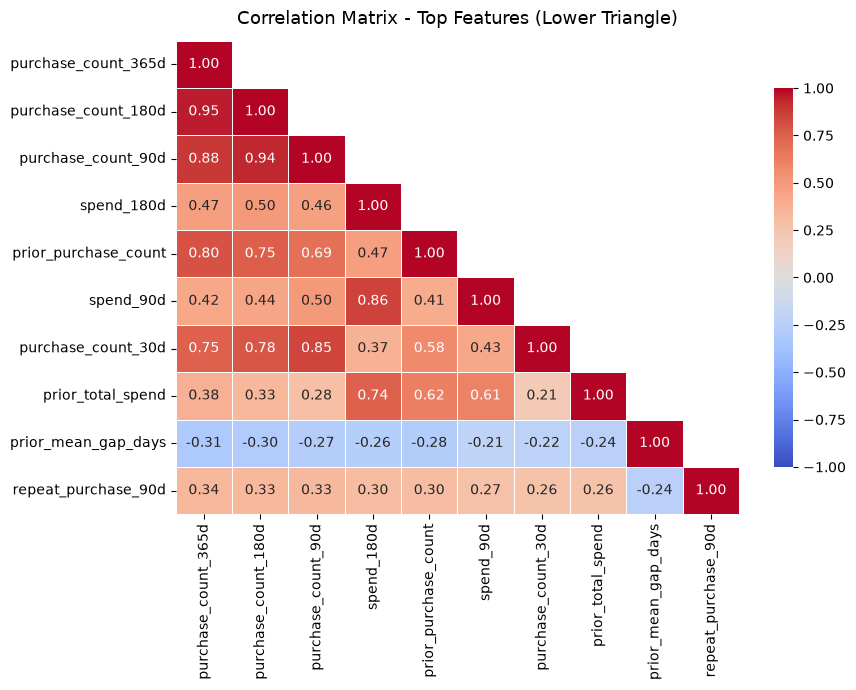

In [12]:
# Select numerical columns and the target
target = 'repeat_purchase_90d'
id_like = ['customer_id', 'ID', 'random_noise']
numeric_cols = [c for c in df_cleaned.columns if c != target and c not in id_like and pd.api.types.is_numeric_dtype(df_cleaned[c])]


# Calculate correlations with the target
corr_series = df_cleaned[numeric_cols + [target]].corr()[target].sort_values(ascending=False)

print("--- Top 5 Positive Correlations with Repurchase ---")
print(corr_series.drop(target).head(5))

print("\n--- Top 5 Negative Correlations with Repurchase ---")
print(corr_series.drop(target).tail(5))

# Calculate the correlation matrix for the top features
top_corr_features = corr_series.drop(target).abs().nlargest(9).index.tolist() + [target]
corr_matrix = df_cleaned[top_corr_features].corr()

# Create a mask to hide the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

# Generate the heatmap with only the lower triangle
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix, 
    mask=mask,          # Applies the upper triangle mask
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=0.5,
    vmin=-1, 
    vmax=1,
    cbar_kws={"shrink": .8}
)
plt.title("Correlation Matrix - Top Features (Lower Triangle)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

**Conclusion 1.6 (target):** The strongest positive correlations with the target are the purchase counts (`purchase_count_365d` ≈ 0.34, `purchase_count_180d` ≈ 0.33, `purchase_count_90d` ≈ 0.33), followed by `spend_180d` and `prior_purchase_count` (≈ 0.30). The strongest negative ones are the gap features (`prior_mean_gap_days` ≈ −0.24, `prior_std_gap_days` ≈ −0.20, `days_since_previous_purchase` ≈ −0.20). All correlations are moderate (|r| below 0.35), so no single feature predicts repurchase on its own, and the many purchase-count features are strongly correlated with each other (see heatmap), which again calls for feature selection.

financial total columns: ['Total a Pagar', 'Total Bruto', 'Total Liquido']


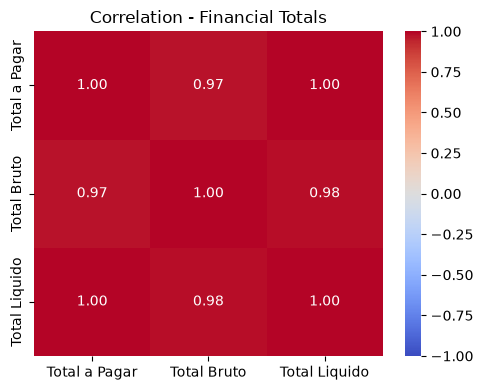

In [13]:
fin_cols = [c for c in df_cleaned.columns 
            if re.search(r"bruto|l[ii]quido|pagar", c, flags=re.I) and pd.api.types.is_numeric_dtype(df_cleaned[c])]

print("financial total columns:", fin_cols)

if len(fin_cols) >= 2:
    plt.figure(figsize=(5, 4))
    sns.heatmap(df_cleaned[fin_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Correlation - Financial Totals")
    plt.tight_layout()
    plt.show()

**Conclusion (financial totals):** `Total a Pagar`, `Total Bruto` and `Total Liquido` are almost perfectly correlated: 0.97 between `Total Bruto` and `Total a Pagar`, 0.98 between `Total Bruto` and `Total Liquido`, and 1.00 between `Total Liquido` and `Total a Pagar`. They carry practically the same information, so keeping all three only adds redundancy and multicollinearity. During feature selection we should keep just one of them, or let the regularised model discard the others.

#### Train vs Test: do the feature relationships stay the same?
The heatmaps below compare the correlation structure of the top features in train and test (both after negative values were masked).

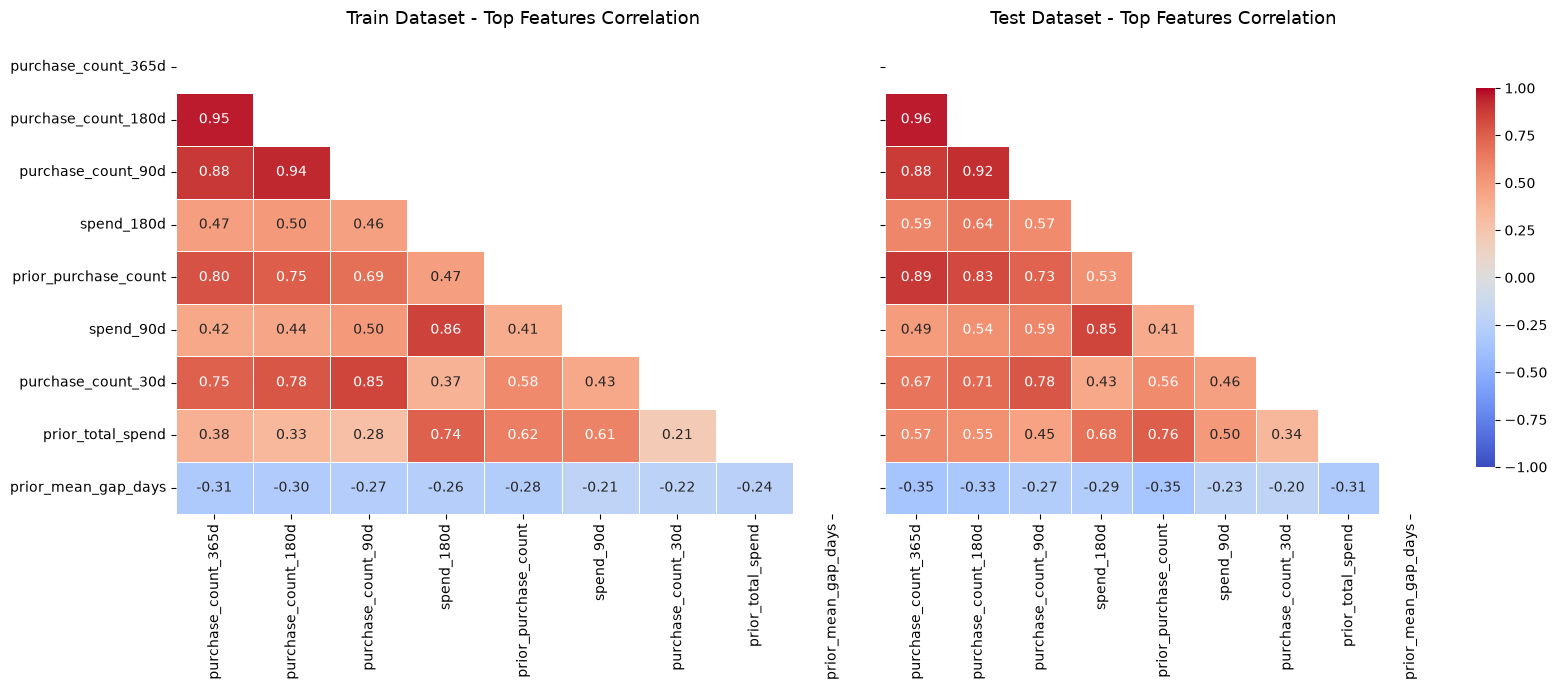

In [14]:
# Define the Top Features identified in the training analysis (without the target)
top_features = [
    'purchase_count_365d',
    'purchase_count_180d',
    'purchase_count_90d',
    'spend_180d',
    'prior_purchase_count',
    'spend_90d',
    'purchase_count_30d',
    'prior_total_spend',
    'prior_mean_gap_days',
]

# Calculate correlation matrices for the same variables in the Training and Test sets
corr_train = df_cleaned[top_features].corr()
corr_test = df_test[top_features].corr()

# Mask to hide the top triangle
mask = np.triu(np.ones_like(corr_train, dtype=bool))

# Set up a figure with 2 subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# Training Dataset Heatmap
sns.heatmap(
    corr_train,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[0],
    cbar=False,
)
axes[0].set_title(
    'Train Dataset - Top Features Correlation', fontsize=13, pad=12
)

# Test Dataset Heatmap
sns.heatmap(
    corr_test,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={'shrink': 0.8},
)
axes[1].set_title(
    'Test Dataset - Top Features Correlation', fontsize=13, pad=12
)

plt.tight_layout()
plt.show()


#### Summary of Insights from Train vs Test Correlations
* **Same structure:** The test correlation matrix closely mirrors the train one. The strongest clusters are almost identical, e.g. `purchase_count_180d` vs `purchase_count_365d` (0.96 in test vs 0.95 in train) and `spend_90d` vs `spend_180d` (0.85 vs 0.86). Feature selection decisions made on train should therefore remain meaningful for test.
* **Not identical:** Some pairs move noticeably, e.g. `prior_purchase_count` vs `purchase_count_365d` (0.80 in train, 0.89 in test) and `prior_total_spend` vs `spend_180d` (0.74 vs 0.68). Relationships are preserved, but the data is not identically distributed, as section 1.7 shows.
* **Recency dynamics:** `prior_mean_gap_days` is negatively correlated with all the count and spend features in both splits.

### 1.7. Train vs Test Drift Analysis
The test set comes from a later period (temporal split), so we check how much its distribution moved away from train: date ranges, repeat rate over time, per-feature Kolmogorov-Smirnov statistics and unseen categories.

In [15]:
from scipy.stats import ks_2samp

d_tr = pd.to_datetime(df["purchase_date"], errors="coerce")
d_te = pd.to_datetime(df_test["purchase_date"], errors="coerce")
print("train purchase_date:", d_tr.min(), "->", d_tr.max())
print("test  purchase_date:", d_te.min(), "->", d_te.max())

print("\nTarget distribution (train):")
print(df["repeat_purchase_90d"].value_counts(normalize=True).round(3).to_dict())

print("\nRepeat rate and number of rows by year (train):")
by_year = df.groupby(d_tr.dt.year)["repeat_purchase_90d"].agg(["mean", "size"]).round(3)
print(by_year.rename(columns={"mean": "repeat_rate", "size": "rows"}).to_string())

num_cols = [c for c in df_test.select_dtypes("number").columns if c not in ["ID", "customer_id", "random_noise"]]
ks = {c: ks_2samp(df_cleaned[c].dropna(), df_cleaned_test[c].dropna()).statistic for c in num_cols}
print("\nKS statistic train vs test (top 10):")
print(pd.Series(ks).sort_values(ascending=False).head(10).round(3).to_string())

if "commercial_zone" in df.columns:
    unseen = ~df_test["commercial_zone"].isin(set(df["commercial_zone"].dropna()))
    print(f"\ntest rows with a commercial_zone not present in train: {unseen.sum()} ({100 * unseen.mean():.1f}%)")

train purchase_date: 2015-07-11 00:00:00 -> 2025-02-15 00:00:00
test  purchase_date: 2025-05-24 00:00:00 -> 2026-10-06 00:00:00

Target distribution (train):
{1: 0.559, 0: 0.441}

Repeat rate and number of rows by year (train):
               repeat_rate  rows
purchase_date                   
2015.0               0.534   335
2016.0               0.514   420
2017.0               0.633   670
2018.0               0.538   716
2019.0               0.522   646
2020.0               0.594   670
2021.0               0.549   782
2022.0               0.481   628
2023.0               0.581   767
2024.0               0.602   757
2025.0               0.628    78

KS statistic train vs test (top 10):
customer_tenure_days         0.462
prior_total_spend            0.318
prior_purchase_count         0.313
prior_max_purchase_value     0.256
Total Desc_ Linha            0.243
spend_365d                   0.209
prior_mean_purchase_value    0.181
prior_min_purchase_value     0.180
prior_std_purchase_value 

**Conclusion 1.7 / overall conclusion:** Train and test show a **moderate distribution shift**, which is expected from a temporal split.
* **Time:** train covers 2015-07 to 2025-02 and test covers 2025-05 to 2026-10, with a gap of about three months in between (consistent with the 90-day horizon of the target).
* **Scales:** the mean *Total a Pagar* rises from about 926 in train to about 1251 in test.
* **Customer mix:** about 21% of the test rows belong to commercial zones never seen in train.
* **Largest shifts (KS):** `customer_tenure_days` (0.46), `prior_total_spend` (0.32) and `prior_purchase_count` (0.31). This is partly mechanical: with time passing, customers accumulate more tenure and more purchases.
* **Relationships:** the correlations between features are largely preserved (see the heatmaps in 1.6).

Therefore we cannot claim the absence of covariate shift. This is why the project validates with **temporal splits** (never random ones), fits every encoder, imputer and scaler on training data only, and handles unseen categories (e.g. `commercial_zone`) with `handle_unknown="ignore"`.

**Next:** [Data Cleaning](2_DataCleaning.ipynb)